First five records:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  

Dataset Shape:
(768, 9)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness 

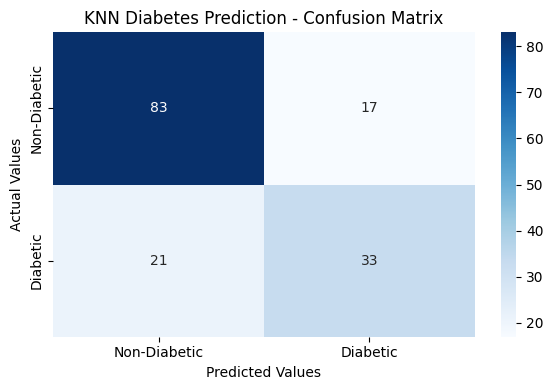

In [2]:
# K-Nearest Neighbors (KNN) for Diabetes Prediction

# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')


# Step 2: Load the dataset
df = pd.read_csv("diabetes.csv")

print("First five records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())


# Step 3: Separate features and target
X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)


# Step 4: Replace invalid zero values with NaN
# Zero is not a valid measurement for these medical features.
zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

X[zero_columns] = X[zero_columns].replace(0, np.nan)


# Step 5: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# Step 6: Preprocessing and KNN model
# Fill missing values using training-set medians.
# Scale features because KNN uses distance calculations.

model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])


# Step 7: Train the KNN model
model.fit(X_train, y_train)

print("\nKNN Model Trained Successfully!")


# Step 8: Predict test data
y_pred = model.predict(X_test)

print("\nPredicted Values:")
print(y_pred)


# Step 9: Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


# Step 10: Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

print("\n========== MODEL PERFORMANCE ==========")

print("Accuracy  :", round(accuracy * 100, 2), "%")
print("Error Rate:", round(error_rate * 100, 2), "%")
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))


# Step 11: Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Non-Diabetic', 'Diabetic'],
    zero_division=0
))


# Step 12: Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)

plt.title("KNN Diabetes Prediction - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.tight_layout()
plt.show()